# PDNO con simbolos parabolicos: calor 2D

Mismo experimento que `06_pdno_calor_1d.ipynb` en $\mathbb T^2$: se aprende el operador solucion $u_0\mapsto u(t)$ del calor con el PDNO lineal, con los datos de `03_calor_2d.ipynb`.

Arquitectura (PDNO, Shin et al., 2024, ec. (1)), simbolo par $a_{\text{par}}$, configuracion lineal y funcion de perdida: ver `06_pdno_calor_1d.ipynb`, introduccion. Aqui la red es el semigrupo $u(t)=e^{-t\bar a(D)}u_0$ con $\bar a=a_{\text{par}}$ ($L=1$, $\tau=1$).

Referencia: $a(k)=|k|^2$ (`HeatSymbol`), $n=2$, $m=2$, $\rho=n+1=3$.

# Setup
El codigo de cada seccion esta en `parabolic_symbol.learning.operator_experiment.PDNOExperiment`; cada metodo es una seccion de `06_pdno_calor_1d.ipynb`.

- **Datos:** los GRF de `03` en la malla de $128\times128$ puntos, $k_{\text{cap}}=32$, con particion **por condicion inicial**: la validacion son $u_0$ nuevas en `TRAIN_TIMES` (early stopping); la prueba, las $20$ $u_0$ de prueba en `TEST_TIMES`.
- **$\kappa$, $(c,C)$ y $C_\alpha$:** solo con las $u_0$ de entrenamiento (`ds.rows_train`), con $m=2$.
- **Entrenamiento y barrido:** `TRAIN_CONFIG` (valores por defecto de `OperatorTrainingConfig` salvo `patience=60`, con `class_C_source="data"` y $k_{\max}=k_{\text{cap}}$) y el barrido `SWEEP` de la MLP del simbolo, con la arquitectura del PDNO fija. Se elige la corrida de menor $L^2$ relativa de validacion.
- **Precision:** `float32` en todo (datos, modelo, entrenamiento, evaluacion, comprobaciones y modelo guardado). Los GRF se generan con numpy y se pasan a `float32` antes de que los vea el modelo.

La celda de parametros reune todo lo configurable.

In [1]:
from pathlib import Path

import numpy as np
import torch

from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.learning.operator_experiment import PDNOExperiment
from parabolic_symbol.learning.operator_training import OperatorTrainingConfig
from parabolic_symbol.utils import default_device

In [2]:
# ---------------------------------------------------------------- parametros
# Precision y device: float32 en todo (datos, modelo, entrenamiento, barrido, evaluacion,
# comprobaciones y modelo guardado).
DEVICE = default_device()
DTYPE = torch.float32

# Datos: como en 03.
REFERENCE = HeatSymbol(n=2)    # a(k) = |k|^2
M = 2.0                        # orden del simbolo aprendido
RESOLUTION = 128               # malla 128 x 128
K_CAP = 32                     # filas espectrales |k|_inf <= k_cap para (c, C) y C_alpha; k_max = k_cap
SEED = 0                       # 100 u0 de entrenamiento (TRAIN_TIMES) y 20 de prueba (TEST_TIMES)
VAL_FRACTION = 0.2             # fraccion de las u0 de entrenamiento que va a validacion
DELTA = 0.1                    # margen de la banda (c, C)
ESTIMATE_TOL = 1e-10           # filtro de senal de estimate_symbol

# Extrapolacion temporal: apagada. Ejemplo (t en [1, 2], todos > max(TRAIN_TIMES) = 0.95):
# EXTRAPOLATION_TIMES = np.linspace(1.0, 2.0, 11)
EXTRAPOLATION_TIMES = None

# Modelo: configuracion lineal del PDNO, la de 06. La MLP del simbolo y el weight decay salen del barrido.
ARCH = dict(width=1, use_W=False, bias=False, activation="identity", lift="identity", project="identity")
N_LAYERS = 1                   # L
LEARN_TAU = False              # tau fijo en 1/L
SYMBOL_HIDDEN = (64, 64, 64)   # solo para el modelo sin entrenar de las comprobaciones (seccion 3)
MODEL_SEED = 0

# Entrenamiento: valores por defecto de OperatorTrainingConfig salvo patience=60, con C_alpha de los datos.
TRAIN_CONFIG = OperatorTrainingConfig(k_max=K_CAP, class_C_source="data", patience=60)

# Barrido de la MLP del simbolo: el de 02-06 (SWEEP de learning/experiment.py), 30 corridas.
SWEEP = dict(
    depths=(2, 3, 4),
    widths=(32, 64, 128),
    dropout=0.2,
    dropout_layers=("none", "middle"),
    weight_decays=(0.0, 1e-4),
)

RESULTS = Path("../results/07_pdno_calor_2d")   # tablas (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)
print(f"device = {DEVICE}  |  dtype = {DTYPE}")

device = cuda  |  dtype = torch.float32


In [3]:
calor = PDNOExperiment(
    reference=REFERENCE, m=M, resolution=RESOLUTION, k_cap=K_CAP, results=RESULTS, train_config=TRAIN_CONFIG, dtype=DTYPE,
    sweep_grid=SWEEP, device=DEVICE, seed=SEED, val_fraction=VAL_FRACTION, delta=DELTA,
    estimate_tol=ESTIMATE_TOL, extrapolation_times=EXTRAPOLATION_TIMES, arch=ARCH,
    n_layers=N_LAYERS, learn_tau=LEARN_TAU, symbol_hidden=SYMBOL_HIDDEN, model_seed=MODEL_SEED,
)

## 1. Datos

`field_datasets` genera los mismos GRF que 03 / 05 y los devuelve como campos $u_0$ de forma `(n_ic, 128, 128)` y $u$ de forma `(n_ic, T, 128, 128)`, con todos los modos de la malla, en `DTYPE`. Particion por condicion inicial y comprobaciones de disjuncion: ver `06_pdno_calor_1d.ipynb`, seccion 1.

In [4]:
display(calor.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 128x128: 21450 pares (k, t) con |k|_inf <= 32 -> 2,145,000 muestras
  ventana de k: 2145 k, |k|_inf <= 32, |k| in [0, 45.3]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 128x128: 42900 pares (k, t) con |k|_inf <= 32 -> 858,000 muestras
  ventana de k: 2145 k, |k|_inf <= 32, |k| in [0, 45.3]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (128, 128)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (128, 128)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (128, 128)

k_max = k_cap = 32
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
entrenamiento y validacion disjuntos: True
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 1.340  (> 0: disjunta)
filas espectrales para la banda y las C_alpha: 1,716,

,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00


**Condiciones iniciales y evolucion.** Dos $u_0$ de entrenamiento y la solucion exacta en algunos tiempos de `TRAIN_TIMES`, cada $u_0$ y cada tiempo en su imagen, con la misma escala de color.

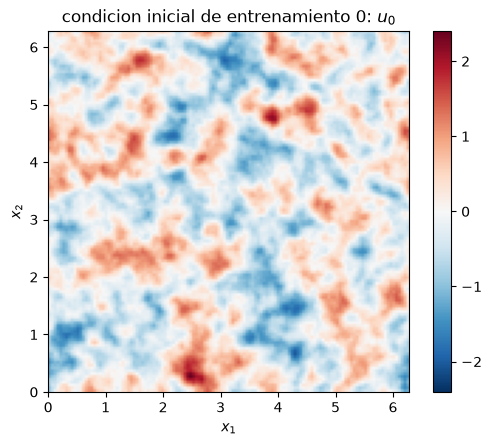

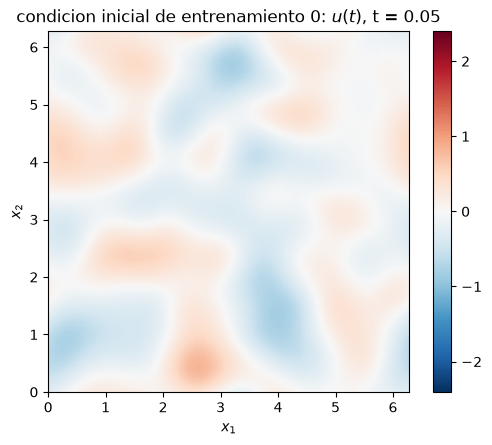

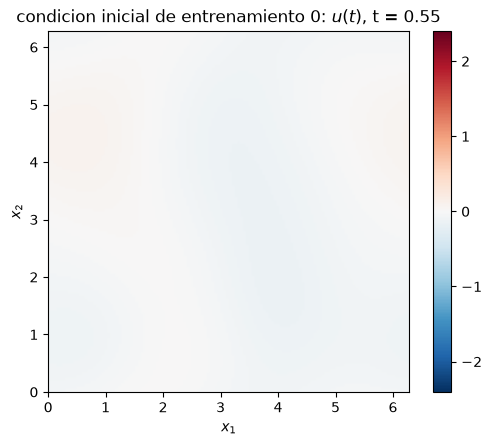

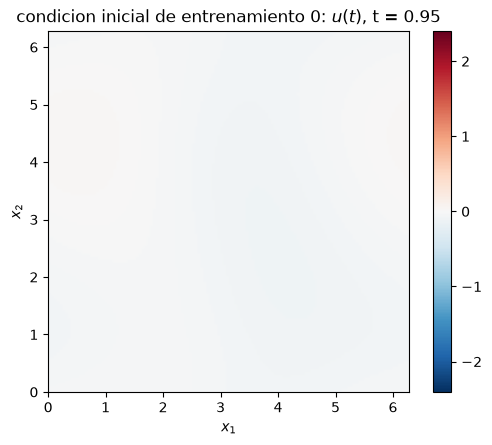

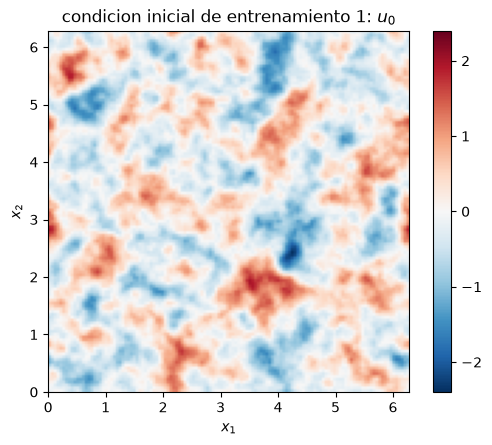

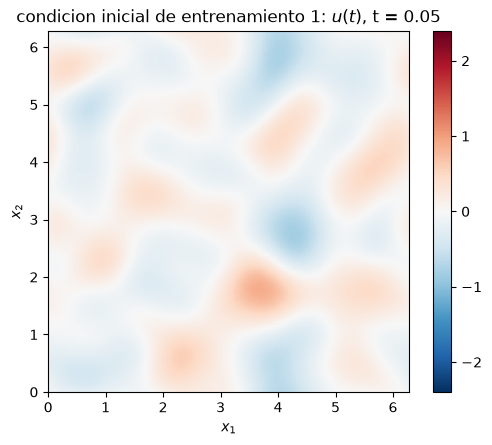

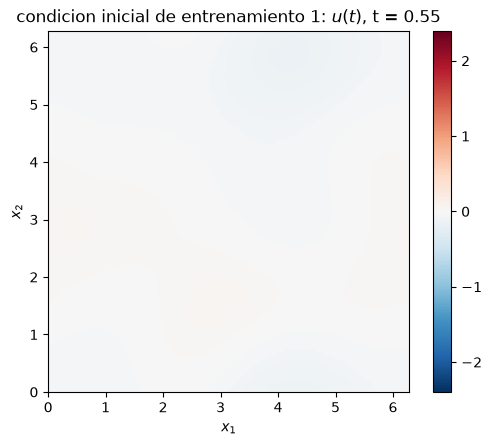

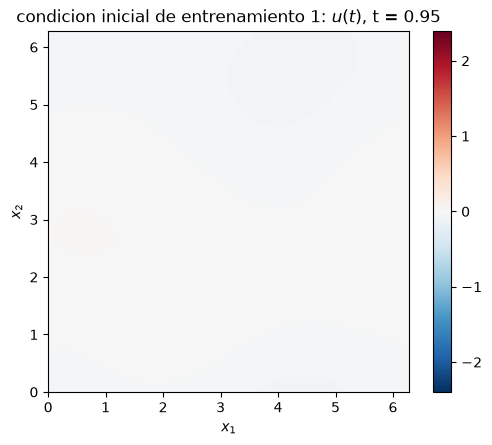

In [5]:
calor.initial_conditions()

## 2. Banda $(c,C)$, $\kappa$ y constantes $C_\alpha$

Como en 06, sobre `ds.rows_train` (las filas espectrales de las $u_0$ de entrenamiento): $\hat a(k)$, $(c,C)$ con $\delta=0.1$, $\kappa=$ `theoretical_kappa()` y las $C_\alpha$ con margen $1.5$ para todos los $\alpha$ con $|\alpha|\le\rho=n+1=3$ ($10$ multiindices en $\mathbb T^2$). Las del oraculo son solo comparacion.

In [6]:
display(calor.estimate_constants())

estimate_symbol: 131,200 de 1,716,000 pares (k, t) con senal (tol=1e-10); 746 de 2145 k de entrenamiento
  ventana usada: 746 k, |k|_inf <= 21, |k| in [0, 21.4]
(c, C) de los datos = (0.4500, 1.0976)   m = 2, ventana: 745 k, |k|_inf <= 21, |k| in [1, 21.4]
kappa teorico       = 3.1427   (omega = 1)
C_alpha estimadas   = 10 multiindices, |alpha| <= rho = 3


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0, 0)",1.496732,1.499268,746
"(0, 1)",3.354102,3.354102,703
"(1, 0)",3.354102,3.354102,724
"(0, 2)",3.000032,3.000000,660
"(1, 1)",0.000643,1.499268,682
"(2, 0)",3.000033,3.000000,702
"(0, 3)",0.001133,1.499268,617
"(1, 2)",0.000643,1.499268,640
"(2, 1)",0.000719,1.499268,661


## 3. Comprobaciones antes de entrenar

Con un modelo recien construido (pesos aleatorios, MLP `SYMBOL_HIDDEN`, modo eval), como en 06:

- **Paridad:** $\max_k|a_{\text{par}}(k)-a_{\text{par}}(-k)|$ en toda la rejilla $|k_i|\le64$ (Nyquist), incluidos los $k$ con $k_2=0$ y $k_2<0$: la costura del medio espacio de `rfftn` es toda la recta $k_2=0$. Debe ser $0$.
- **Reduccion:** el PDNO frente a $e^{-t\bar a(k)}\hat u_0(k)$ en el layout de los datos (`rfftn`) y, ademas, con la FFT completa (`fftn`, todos los modos, sin medio espacio). Error maximo relativo $\max_x|u_\theta-u|/\max_x|u|$.
- **Semigrupo:** $\max\|S(t+s)u_0-S(t)S(s)u_0\|/\|u_0\|$ para varios pares $(t,s)$.

Todo en `DTYPE`: reduccion y semigrupo deben quedar en unas pocas unidades del redondeo de float32 ($\sim10^{-6}$).

In [7]:
display(calor.checks())

tau = [1.]
capa 0: max |a(k) - a(-k)| = 0.000e+00   (|k_i| <= 64, 16,641 k)


,valor,esperado
comprobacion,,
"paridad: max |a(k) - a(-k)|, |k_i| <= 64, 16,641 k",0.000000e+00,0
"reduccion: max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",2.559950e-07,~1e-06
"reduccion (fftn completa): max error relativo (4 u0 de prueba, t = [0.05, 0.5, 1.0])",3.220504e-07,~1e-06
semigrupo: max ||S(t+s)u0 - S(t)S(s)u0|| / ||u0|| (5 pares),8.330732e-08,~1e-06


## 4. Barrido de la MLP del simbolo

El barrido de la celda de parametros (`SWEEP`, el de 02-06): $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas, dropout $0.2$ en `none` o `middle` y weight decay $\{0,10^{-4}\}$, $30$ corridas con la arquitectura del PDNO fija y `TRAIN_CONFIG`. Cada una es `train_operator` con `rows=ds.rows_train` (`class_C_source="data"`) y early stopping con paciencia $60$ sobre la perdida total de validacion. Detalles: ver `06_pdno_calor_1d.ipynb`, seccion 4.

In [8]:
calor.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0030 | 107.9s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0030 | 105.3s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0022 | 107.4s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0022 | 107.4s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0021 | 124.3s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0021 | 123.7s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0032 | 110.1s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0032 | 111.4s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.1757 |  30.6s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.1757 |  30.1s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0029 | 117.0s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0029 | 118.0s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.1754 |  32.6s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.1752 |  33.0s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0022 | 150.2s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0023 | 151.0s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.1751 |  56.0s
[ 18/30] 3x128 drop[1] wd=1e-04

In [9]:
barrido, por_eje = calor.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,128,OFF,0.0001,0.002073,0.002494,0.710610
1,2,128,OFF,0.0000,0.002083,0.002505,0.710611
2,4,128,OFF,0.0001,0.002098,0.002562,0.710589
3,3,128,OFF,0.0000,0.002171,0.002593,0.710588
4,2,64,OFF,0.0001,0.002202,0.002638,0.710594
5,2,64,OFF,0.0000,0.002226,0.002664,0.710598
6,4,128,OFF,0.0000,0.002257,0.002691,0.710577
7,3,128,OFF,0.0001,0.002273,0.002693,0.710592
8,3,64,OFF,0.0000,0.002895,0.003188,0.710626
9,3,64,OFF,0.0001,0.002910,0.003199,0.710626


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.002073,0.002494,0.710538
"ON p=0.2 capas[1,2]",6,0.175166,0.178255,0.550984
ON p=0.2 capas[1],6,0.175127,0.178165,0.551570


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.002083,0.002505,0.551002
0.0001,15,0.002073,0.002494,0.550984


### Seleccion: la mejor aproximacion

La corrida de **menor $L^2$ relativa de validacion** (`best_run`). Desde aqui, las secciones 5 a 10 usan la corrida elegida.

In [10]:
display(calor.select())

kappa = theoretical_kappa() = 3.1427
arquitectura elegida    = 2 capas x 128 neuronas (MLP del simbolo)
dropout                 = OFF
weight decay            = 0.0001  (Linear ocultas interiores)
early stopping          = mejor epoca 300 de 300 epocas; se detuvo antes del final: False
tau                     = [1.]
C_alpha de train_operator = las de class_C.csv: True

metricas de validacion en la mejor epoca:
  total             = 2.4944e-03
  rel_l2            = 0.0021
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  clase             = 4.2112e-04
  peor ratio        = 0.7106
  puntos con >1     = 0.00%


total                   0.002494
rel_l2                  0.002073
parabolicidad           0.000000
clase                   0.000421
peor ratio              0.710610
puntos con ratio > 1    0.000000
Name: validacion (mejor epoca), dtype: float64

## 5. Curvas de entrenamiento

Perdida total y cada termino por epoca, en entrenamiento y validacion, cada uno en su imagen (`perdida_total.png`, `perdida_rel_l2.png`, `perdida_parabolicidad.png`, `perdida_clase.png`); la linea punteada marca la epoca restaurada por el early stopping. Las perdidas por epoca se guardan en `historia.csv`, que leen los benchmarks contra el FNO.

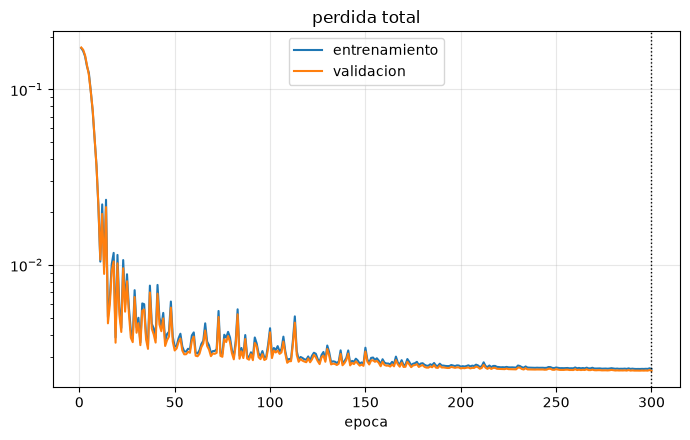

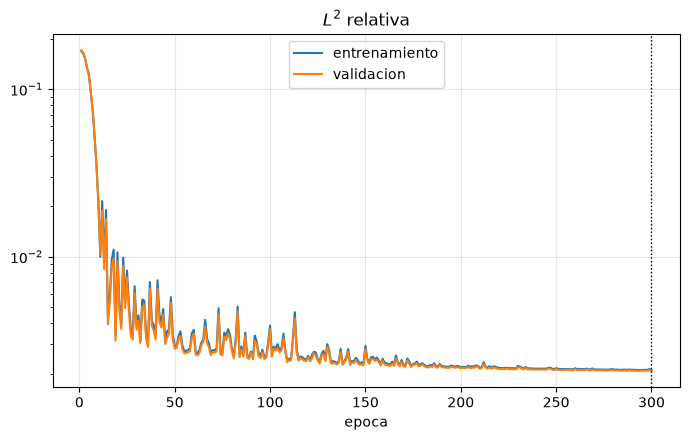

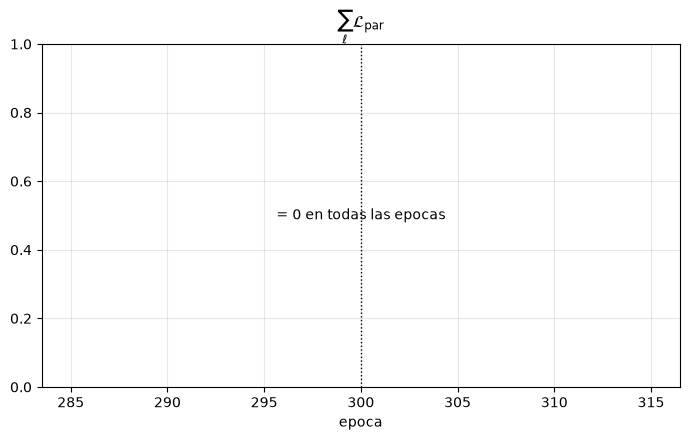

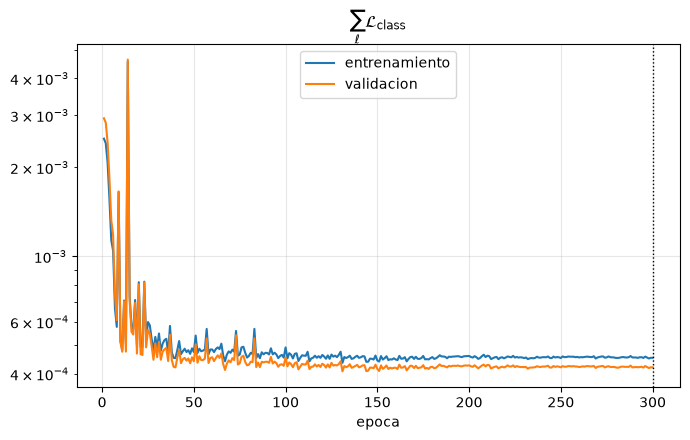

In [11]:
calor.curves()

## 6. Prueba

`field_errors` sobre las $20$ $u_0$ de prueba en `TEST_TIMES`: error relativo $L^2$ en espacio fisico (malla $128\times128$) por condicion inicial y tiempo. Se imprime tambien la $L^2$ relativa sobre los pares $(k,t)$ de prueba con $|k|_\infty\le k_{\max}$, con el simbolo efectivo: la `test_rel_l2` de 05 y del resumen.

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
error relativo L2 (espacio fisico) = 1.7806e-03  (medio; max 1.2274e-02)
error relativo L2 (pares (k, t), |k|_inf <= 32, simbolo efectivo) = 4.8374e-03


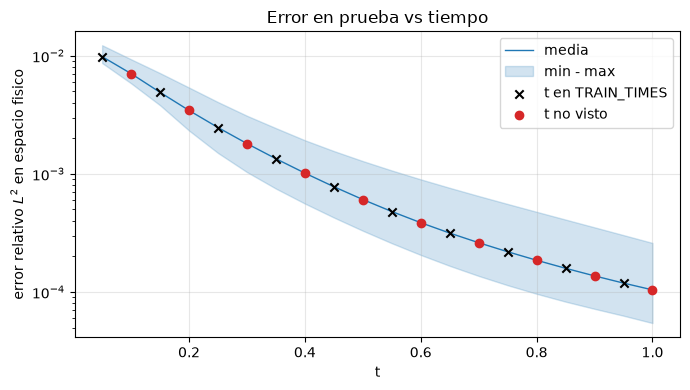

,media,max,en_entrenamiento
t,,,
0.05,0.009833,0.012274,True
0.10,0.007056,0.009333,False
0.15,0.004900,0.007128,True
0.20,0.003443,0.005380,False
0.25,0.002468,0.004053,True
0.30,0.001805,0.003104,False
0.35,0.001343,0.002438,True
0.40,0.001015,0.001925,False
0.45,0.000779,0.001560,True


In [12]:
display(calor.test())

**Campo.** Primera condicion inicial de prueba en algunos tiempos de `TEST_TIMES`: solucion exacta, la del PDNO y su diferencia, cada campo y tiempo en su imagen (`campo_exacta_t*.png`, `campo_pdno_t*.png`, `campo_error_t*.png`); exacta y PDNO comparten la escala de color.

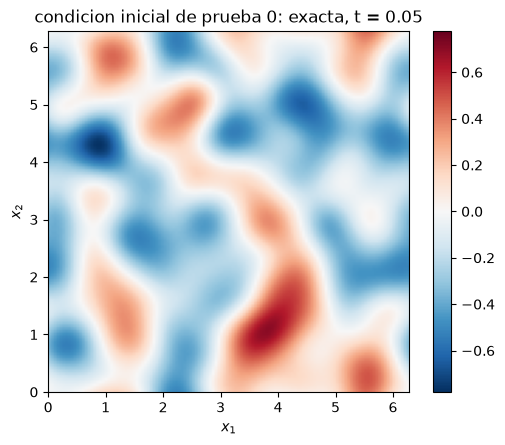

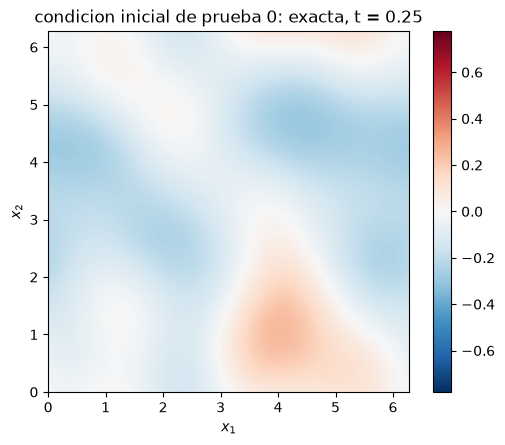

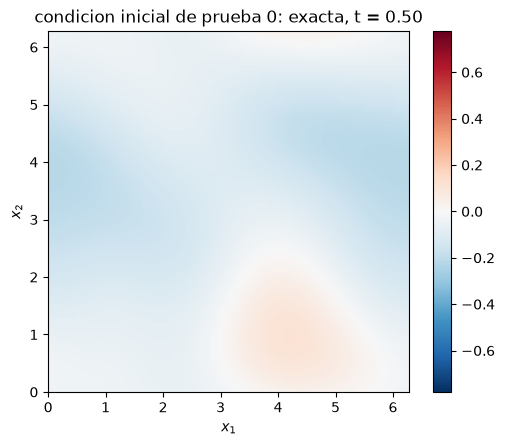

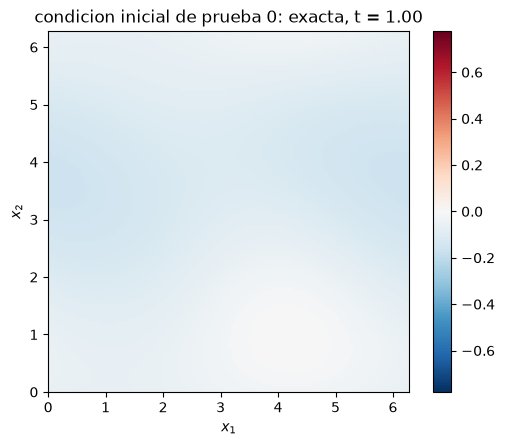

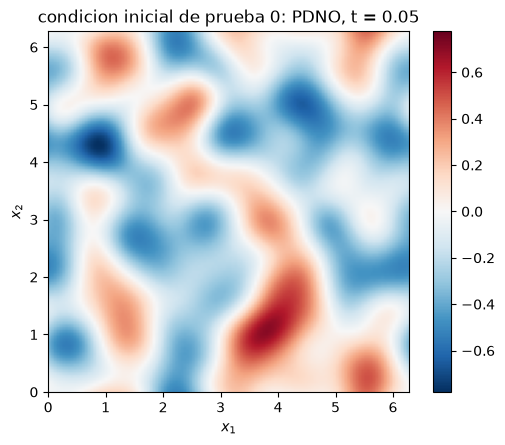

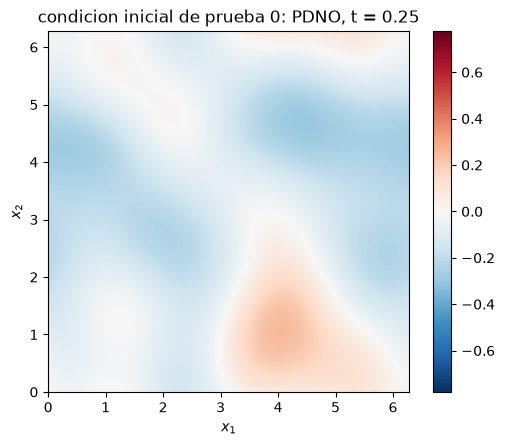

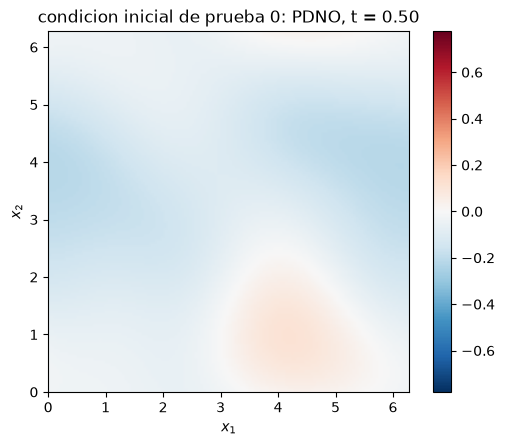

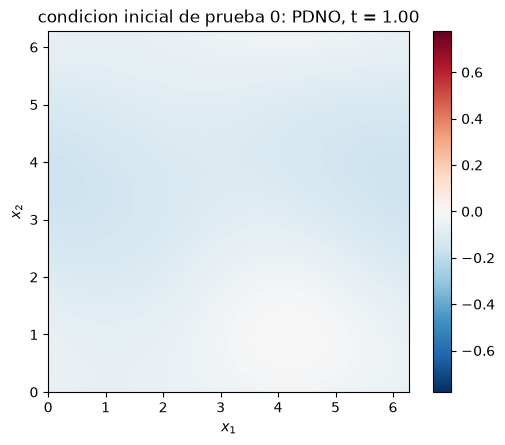

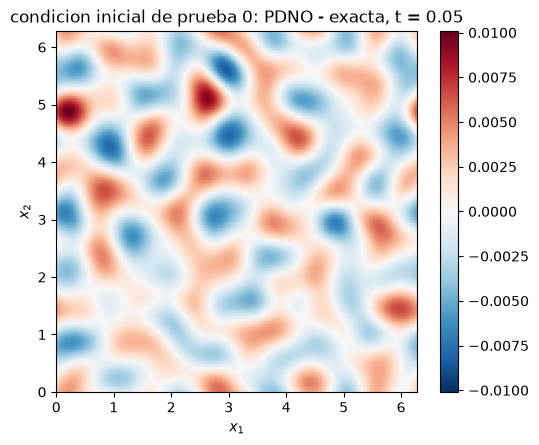

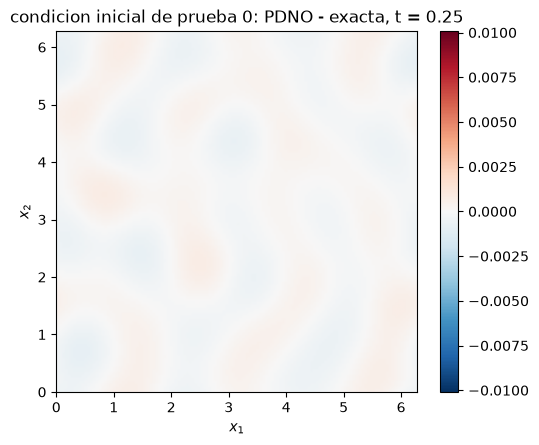

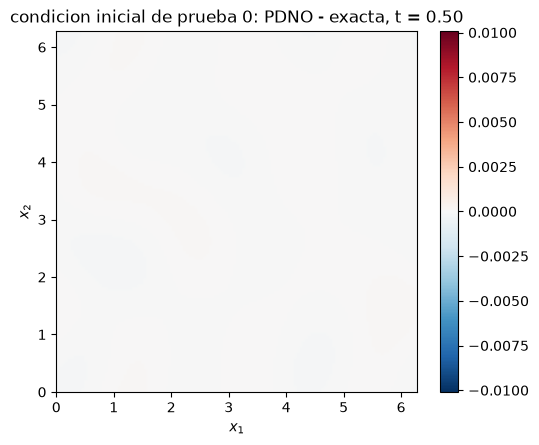

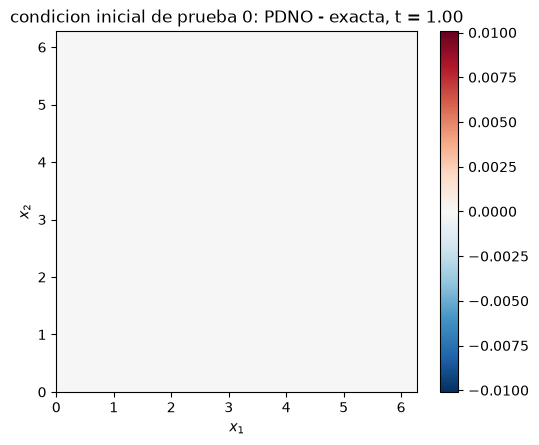

In [13]:
calor.field_figure()

## 7. Simbolo aprendido

El simbolo efectivo $\bar a(k)$ frente a $|k|^2$ en todos los modos de la malla, $|k_i|\le64$. El simbolo es radial, asi que se dibuja contra $|k|$; la ventana de entrenamiento es el cuadrado $|k|_\infty\le k_{\max}=32$, y los puntos dentro y fuera de ella van en colores distintos. En `simbolo_banda.png`, $\bar a(k)/\langle k\rangle^m$, que esta siempre en la banda $(c,C)$ por construccion.

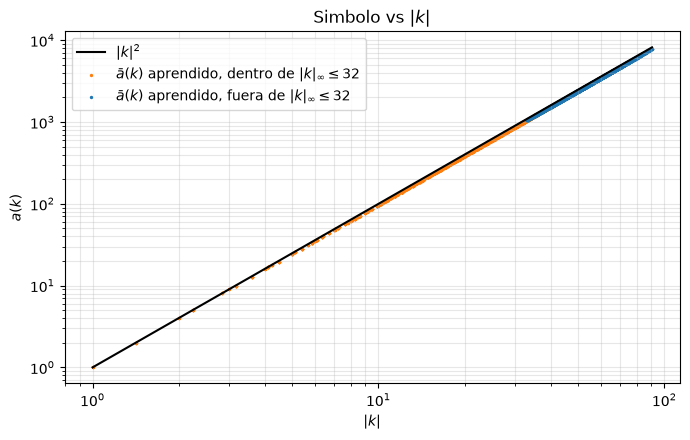

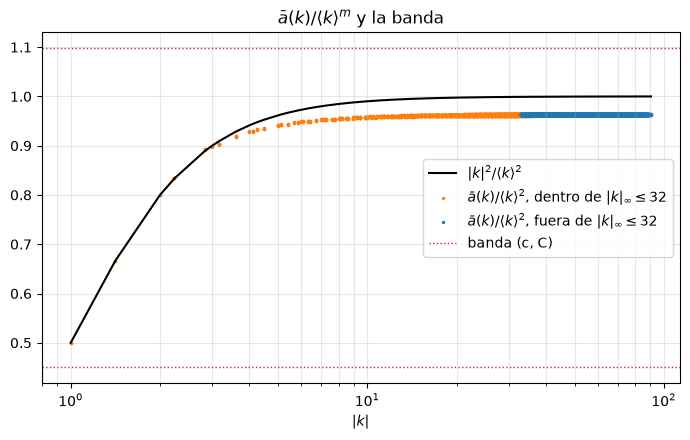

In [14]:
calor.symbol_figure()

**Error del simbolo.** $|\bar a(k)-a(k)|/a(k)$ en cada $k$ ($k=0$ se omite), dentro y fuera de la ventana, contra $|k|$ (`error_simbolo.png`) y como mapa sobre $(k_1,k_2)$ (`error_simbolo_mapa.png`).

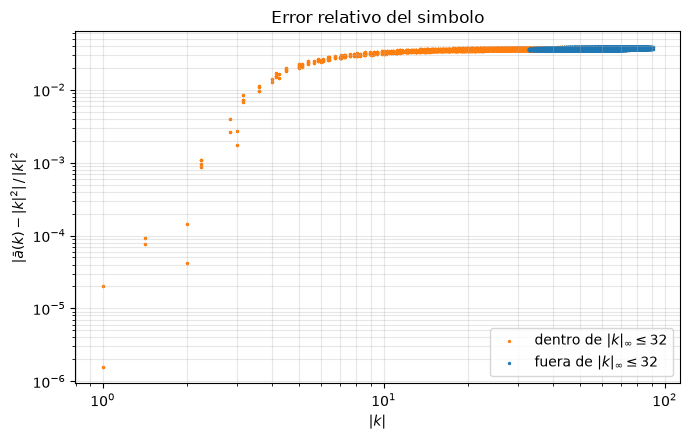

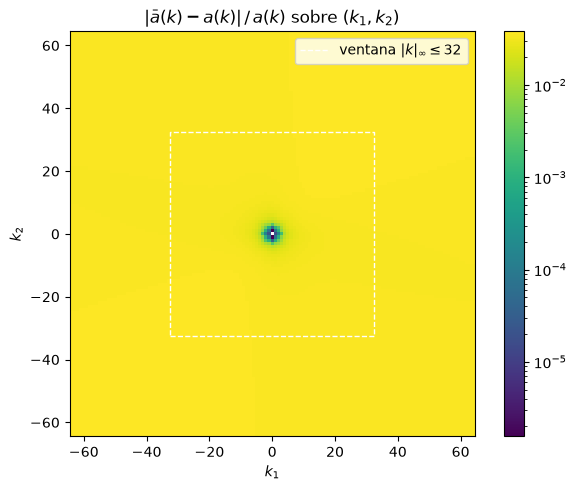

,dentro (|k|_inf <= 32),fuera (|k|_inf > 32)
n,4225.000000,12416.000000
mse,928.217156,19339.022048
rmse,30.466656,139.064812
mae,25.564699,127.954389
max_error,78.138062,313.916992
rel_l2,0.036579,0.036910
error_relativo_medio,0.035102,0.036684
error_relativo_max,0.038162,0.038341


In [15]:
display(calor.symbol_error())

**Multiplicador.** $e^{-t\bar a(k)}$ aprendido (punteado) frente a $e^{-t|k|^2}$ (continuo) sobre el eje $k=(k_1,0)$, $0\le k_1\le k_{\max}$; su diferencia absoluta va en `multiplicador_error.png`.

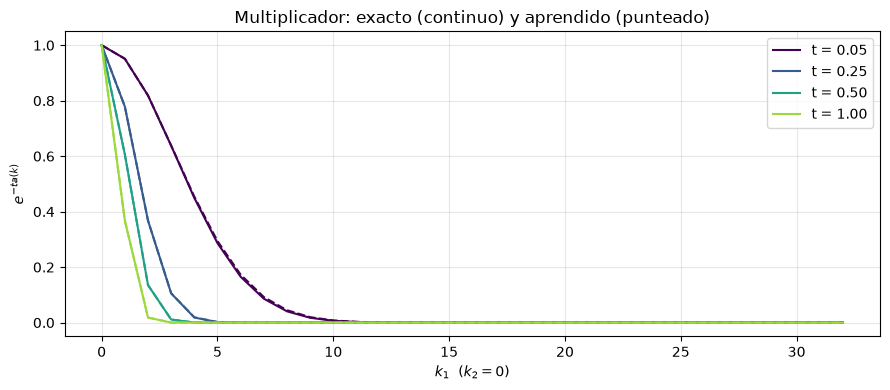

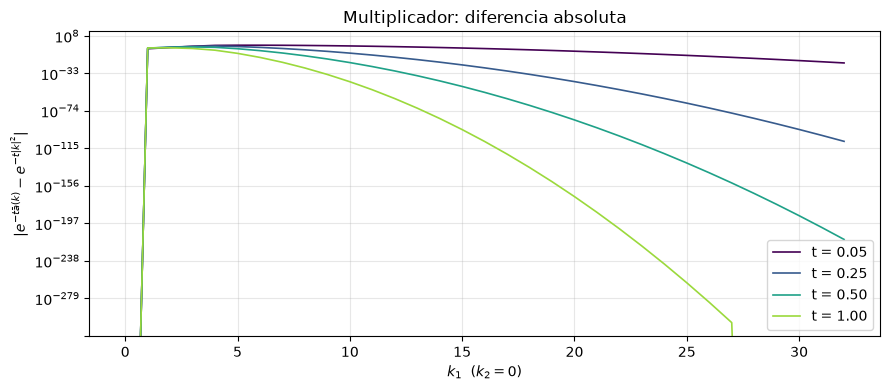

In [16]:
calor.multiplier()

## 8. Certificacion

**Parabolicidad (Def. 2.3).** `ParabolicityVerifier` sobre el simbolo de cada capa y el efectivo, con la rejilla de `GRFExperiment`: $|k_i|\le K$, $K\in\{k_{\max},2k_{\max},3k_{\max}\}$, y `CERT_LAM`. Se cumple si el peor ratio $\hat\kappa/\kappa$ es $\le1$.

**Clase $S^{m,\rho}$ (Def. 2.1).** `SymbolClassVerifier` en ventanas crecientes; es evidencia en una ventana finita, no una prueba sobre todo $\mathbb Z^n$.

In [17]:
display(calor.certification())

kappa usada = 3.1427


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,32,dentro,2640625,0.711224,True
1,capa 0,64,fuera,10400625,0.711224,True
2,capa 0,96,fuera,23280625,0.711224,True
3,efectivo,32,dentro,2640625,0.711224,True
4,efectivo,64,fuera,10400625,0.711224,True
5,efectivo,96,fuera,23280625,0.711224,True


In [18]:
display(calor.symbol_class())

capa 0: consistentes 6 de 10 multiindices
efectivo: consistentes 6 de 10 multiindices
ventana explorada: |k_i| <= 64 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(64),crecim.(12->64),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0, 0)",0,0.947121,0.959593,0.961841,0.964387,1.002647,2.000266,2.0,True,True
1,capa 0,"(0, 1)",1,2.225029,2.225029,2.225029,2.225029,1.000000,0.979106,1.0,True,True
2,capa 0,"(1, 0)",1,2.229342,2.229342,2.229342,2.229342,1.000000,0.978059,1.0,True,True
3,capa 0,"(0, 2)",2,2.021726,2.021726,2.021726,2.021726,1.000000,0.001111,0.0,True,True
4,capa 0,"(1, 1)",2,0.084923,0.084923,0.084923,0.084923,1.000000,0.224169,0.0,True,True
5,capa 0,"(2, 0)",2,2.023191,2.023191,2.023191,2.023191,1.000000,0.001237,0.0,True,True
6,capa 0,"(0, 3)",3,0.775124,0.775124,0.775124,0.775124,1.000000,1.326991,-1.0,True,False
7,capa 0,"(1, 2)",3,0.432537,0.432537,0.432537,0.432537,1.000000,1.695625,-1.0,True,False
8,capa 0,"(2, 1)",3,0.409156,0.409156,0.409156,0.409156,1.000000,1.669405,-1.0,True,False
9,capa 0,"(3, 0)",3,0.778993,0.778993,0.778993,0.778993,1.000000,1.419875,-1.0,True,False


## 9. Extrapolacion temporal

Solo si `EXTRAPOLATION_TIMES` no es `None`: las $u_0$ de prueba en tiempos $t>0.95$. Solo se reporta.

In [19]:
tabla_ext = calor.extrapolation()
if tabla_ext is not None:
    display(tabla_ext)

EXTRAPOLATION_TIMES = None: seccion omitida


## 10. Modelo guardado

`save_operator_model` guarda en `results/07_pdno_calor_2d/modelo.pt` la corrida seleccionada (pesos, `PDNOConfig`, `OperatorTrainingConfig`, $C_\alpha$, dtype y lo necesario para regenerar los datos). Para reconstruirlo sin este notebook:

```python
from parabolic_symbol.learning.operator_training import load_operator_datasets, load_operator_model
model = load_operator_model("results/07_pdno_calor_2d/modelo.pt")
ds = load_operator_datasets("results/07_pdno_calor_2d/modelo.pt", dtype=model.dtype)   # misma semilla, mismos datos
```

La ultima celda recarga el modelo y comprueba que da el mismo error de prueba.

In [20]:
calor.save_model()

modelo guardado en ../results/07_pdno_calor_2d/modelo.pt


PosixPath('../results/07_pdno_calor_2d/modelo.pt')

In [ ]:
calor.check_saved_model()

dtype del modelo cargado = torch.float32
error de prueba (cargado) = 1.780633e-03  |  (entrenado) = 1.780633e-03
identicos: True


True

: 